# Image Classification with Neural Networks
## Comparing ANN and CNN Architectures on MNIST and Fashion-MNIST

**Project focus**: Baseline image classification, data augmentation, knowledge distillation, and comparative model evaluation

In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[]


## Project overview

This project compares **Artificial Neural Networks (ANNs)** and **Convolutional Neural Networks (CNNs)** on two image-classification benchmarks: **MNIST (handwritten digits)** and **Fashion-MNIST (clothing categories)**.

**Goal:** The experiments investigate whether two training strategies—**data augmentation** and **knowledge distillation**—can improve an ANN's performance and reduce its accuracy gap relative to a CNN.

**Experimental configurations**:

| ID | Configuration | Purpose |
|---|---|---|
| C | Baseline CNN | Reference model and distillation teacher |
| A0 | Baseline ANN | Student model without interventions |
| A1 | ANN + data augmentation | Effect of augmentation |
| A2 | ANN + knowledge distillation | Effect of distillation |
| A3 | ANN + augmentation + distillation | Combined effect |



**Experimental principles**
- Both datasets use 28 × 28 grayscale images with ten classes.
- Training, validation, and test splits are kept separate.
- Augmentation is applied to training data only.
- The CNN teacher is frozen during distillation; only the ANN student is updated.
- Model comparisons use consistent ANN architecture and training settings.
- Final metrics are calculated on the held-out test sets after model development.

The results are empirical rather than guaranteed: a technique is considered helpful only when the measured results support that conclusion.

## 1. Environment and Reproducibility

Neural-network experiments involve randomness from weight initialization, mini-batch ordering, and image transformations. The setup below imports the required libraries, fixes random seeds where possible, checks available hardware, and centralizes experiment settings.


For reproducible comparisons, the ANN variants use a consistent architecture, optimizer, learning rate, batch size, epoch budget, and data split. GPU operations may still introduce small run-to-run differences.

In [ ]:
  # YOUR CODE HERE — imports, seeds, and device check
import os, random
import numpy as np
import tensorflow as tf

# task 01:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Task 02 :
from tensorflow.keras import layers





SEED = 42

BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
VAL_FRACTION = 0.10
TEMPERATURE = 3.0
ALPHA = 0.5

# YOUR CODE HERE
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPU available:", gpus if gpus else "No GPU, running on CPU")

TensorFlow: 2.21.0
GPU available: No GPU, running on CPU


### Reproducibility Notes

> **Reproducibility**:
<br>
The seed makes the random parts repeatable (initial weights, batch order, the validation split, augmentation). Without it, a difference between two models could just be luck. Why GPU runs still differ: GPUs add numbers in parallel, and the order of those additions can change between runs. Floating-point addition isn’t perfectly associative, so tiny rounding differences appear. Some CUDA algorithms are also non-deterministic by design.

>**Observation 2**:<br>
The ANN architecture, optimizer (Adam), learning rate, batch size, number of epochs, seed, and the same train/validation/test split. For A2 and A3, also the same T and alpha. Only the intervention itself should change.

## 2. Dataset Exploration and Preprocessing

**Concept:** MNIST and Fashion-MNIST each contain 28 × 28 grayscale images across ten classes. Their input dimensions are identical, but their visual recognition challenges differ.

Both datasets are loaded with tf.keras.datasets. A fixed stratified validation split is created from the original training data, pixel values are normalized to [0, 1], and a channel dimension is added. Integer class labels are retained. The official test split remains untouched until final evaluation.

In [ ]:
def prepare_dataset(dataset_name, seed=SEED):
    """Return dict with x_train,y_train,x_val,y_val,x_test,y_test.
    Images: float32 (N,28,28,1) in [0,1]; labels: integer 0..9.
    Use a stratified validation split from the original training set.
    """
    # YOUR CODE HERE
    if dataset_name == "MNIST":
        loader = tf.keras.datasets.mnist
    elif dataset_name == "Fashion-MNIST":
        loader = tf.keras.datasets.fashion_mnist
    else:
        raise ValueError("Unknown dataset")

# YOUR CODE HERE — call for MNIST and Fashion-MNIST
# datasets = {"MNIST": ..., "Fashion-MNIST": ...}

    (x_full, y_full), (x_test, y_test) = loader.load_data()

    x_full = (x_full.astype("float32") / 255.0)[..., np.newaxis]
    x_test = (x_test.astype("float32") / 255.0)[..., np.newaxis]
    y_full = y_full.astype("int64")
    y_test = y_test.astype("int64")

    x_train, x_val, y_train, y_val = train_test_split(
        x_full, y_full,
        test_size=VAL_FRACTION,
        stratify=y_full,
        random_state=seed,
    )
    return {"x_train": x_train, "y_train": y_train,
            "x_val": x_val, "y_val": y_val,
            "x_test": x_test, "y_test": y_test}

datasets = {"MNIST": prepare_dataset("MNIST"),
            "Fashion-MNIST": prepare_dataset("Fashion-MNIST")}

for name, d in datasets.items():
    print(name, d["x_train"].shape, d["x_val"].shape, d["x_test"].shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST (54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)
Fashion-MNIST (54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


### Dataset Inspection and Visualization

For each dataset, the notebook reports the shapes and class counts for the training, validation, and test splits. It also displays labeled training examples, plots class frequencies, and checks the minimum and maximum pixel values. Validation and test images remain unaugmented.


===== MNIST =====

 A. For each dataset, print the shapes and class counts for the three splits 

For train shapes classes count and min/max pixels
    train | images: (54000, 28, 28, 1) | labels: (54000,)
   class counts: [5331, 6068, 5362, 5518, 5258, 4879, 5326, 5638, 5266, 5354]
   pixel min: 0.0 | pixel max: 1.0
For val shapes classes count and min/max pixels
    val | images: (6000, 28, 28, 1) | labels: (6000,)
   class counts: [592, 674, 596, 613, 584, 542, 592, 627, 585, 595]
   pixel min: 0.0 | pixel max: 1.0
For test shapes classes count and min/max pixels
    test | images: (10000, 28, 28, 1) | labels: (10000,)
   class counts: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]
   pixel min: 0.0 | pixel max: 1.0

 B. display at least 12 labeled training images 
 


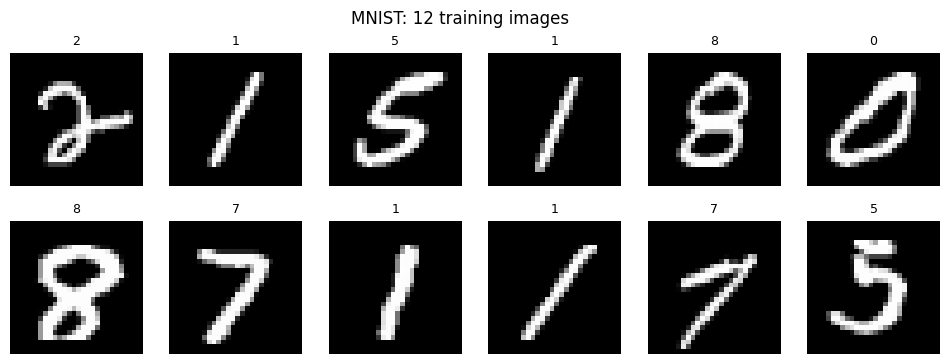


 C. bar chart of training class frequencies



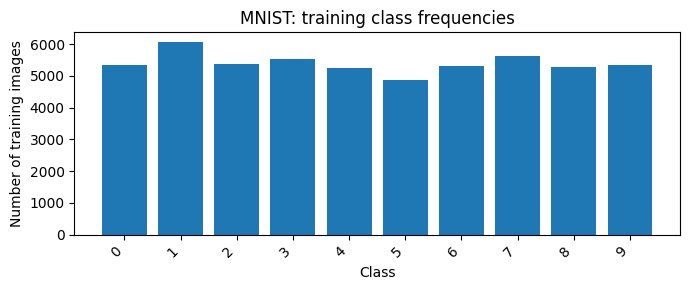


 D. verify val and test were not augmented 

val unmodified: True
test unmodified: True

===== Fashion-MNIST =====

 A. For each dataset, print the shapes and class counts for the three splits 

For train shapes classes count and min/max pixels
    train | images: (54000, 28, 28, 1) | labels: (54000,)
   class counts: [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400]
   pixel min: 0.0 | pixel max: 1.0
For val shapes classes count and min/max pixels
    val | images: (6000, 28, 28, 1) | labels: (6000,)
   class counts: [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]
   pixel min: 0.0 | pixel max: 1.0
For test shapes classes count and min/max pixels
    test | images: (10000, 28, 28, 1) | labels: (10000,)
   class counts: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
   pixel min: 0.0 | pixel max: 1.0

 B. display at least 12 labeled training images 
 


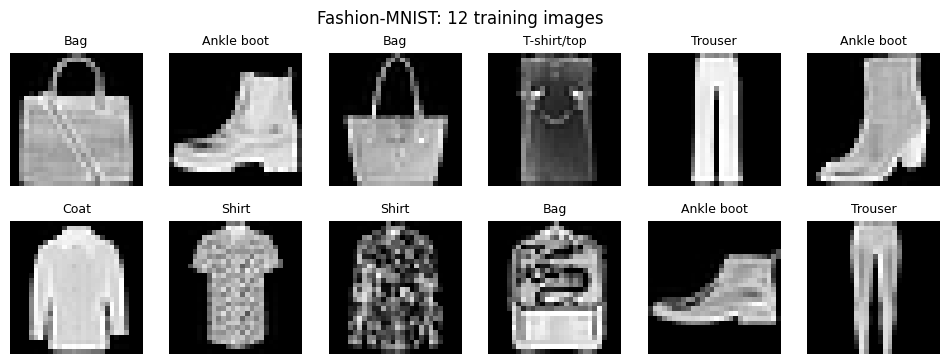


 C. bar chart of training class frequencies



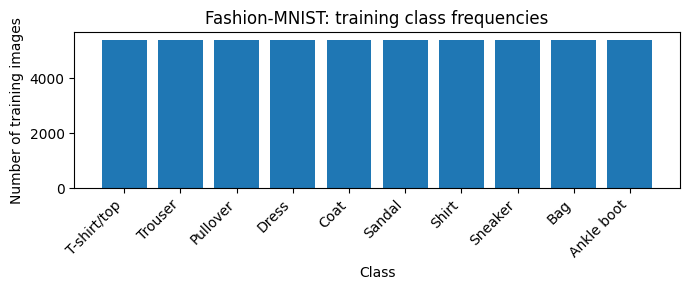


 D. verify val and test were not augmented 

val unmodified: True
test unmodified: True


In [ ]:
import matplotlib.pyplot as plt
#loads the plotting library as plt


fashion_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                 "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
# a list of the 10 clothing names,Labels in the dataset are just numbers 0 to 9,
#                  where 0 means T-shirt, 1 means trouser, and so on.

class_names = {"MNIST": [str(i) for i in range(10)],
               "Fashion-MNIST": fashion_names}
#The dictionary ties each dataset name to its corresponding labels


for name, d in datasets.items():
  # the datasets is dictionary and iteam give the key to name and value to d
  # datasets key = MNIST” and “Fashion-MNIST”.
  # datasets value =  prepare_dataset("dataset_name")

    print("\n=====", name, "=====")

# A. For each dataset, print the shapes and class counts for the three splits
    print("\n A. For each dataset, print the shapes and class counts for the three splits \n")

# shapes, class counts, pixel min/max for each split

    for split in ["train", "val", "test"]:
        # |__  this loop run three time for train val and test
        print(f"For {split} shapes classes count and min/max pixels")

        x = d["x_" + split]
# join the string x_ = x_train get train images from dataset

        y = d["y_" + split] # same fetch the y label of trains

        print("   ",split, "| images:", x.shape, "| labels:", y.shape)
# x.shape - Shape of the image array (samples, height, width, channels)

        print("   class counts:", np.bincount(y).tolist())
# counts how many times each integer appears in y and convert into list


        print("   pixel min:", x.min(), "| pixel max:", x.max())
        # give the smallest and largest pixel value.



# B. display at least 12 labeled training images
    print("\n B. display at least 12 labeled training images \n ")

    # 12 labeled training images
    plt.figure(figsize=(12, 4))
    # |__ creates a blank canvas 12 inches wide and 4 inches tall.

    for i in range(12):

        plt.subplot(2, 6, i + 1)   # i+1 = 0+1 = 1
        # split the grid into 2 row and 6 columns and i+1 pick slot number

        plt.imshow(d["x_train"][i].squeeze(), cmap="gray")

        plt.title(class_names[name][d["y_train"][i]], fontsize=9)
        plt.axis("off")
    plt.suptitle(name + ": 12 training images")
    plt.show()

  # C. bar chart of training class frequencies
    print("\n C. bar chart of training class frequencies\n")

    plt.figure(figsize=(7, 3))
    plt.bar(class_names[name], np.bincount(d["y_train"]))
    plt.xticks(rotation=45, ha="right")
    plt.xlabel("Class")
    plt.ylabel("Number of training images")
    plt.title(name + ": training class frequencies")
    plt.tight_layout()
    plt.show()

    print("\n D. verify val and test were not augmented \n")
    # verify val and test were not augmented:
    # raw pixels are whole numbers 0-255, so (pixel * 255) must be whole numbers.
    # Augmentation (shift/rotate/zoom/elastic) creates in-between values, so this would fail.

    for split in ["val", "test"]:
        scaled = d["x_" + split] * 255
        print(split, "unmodified:", np.allclose(scaled, np.round(scaled), atol=1e-3))

### Dataset Observations


The shape `(N, 28, 28, 1)` means there are N images, each image is 28 pixels high, 28 pixels wide, and has one grayscale channel. I divide pixel values by 255 so they fall between 0 and 1, which gives the model inputs on a consistent scale and helps gradient-based training. The validation set is used to monitor performance and make development decisions, while the test set is kept separate until the final evaluation so it provides an unbiased estimate on unseen data. Fashion-MNIST appears more visually ambiguous because categories such as shirts, T-shirts, pullovers, and coats have similar outlines. MNIST digits are generally clearer, although some handwritten pairs can still look similar. Fashion-MNIST is perfectly balanced: each class has 5,400 training, 600 validation, and 1,000 test images. MNIST is slightly imbalanced: digit 1 has the highest training count (6,068), while digit 5 has the lowest (4,879).

## 3. Model Architecture Design

**Concept:** The ANN processes flattened pixel values, while the CNN uses local convolutional filters and weight sharing to learn spatial image features.

**Architecture requirements**

ANN architecture
`Input(28, 28, 1) → Flatten → Dense hidden layers (ReLU) → 10 logits `

**CNN architecture**

The CNN uses at least two convolutional layers, pooling, a flattening or global-pooling stage, a dense hidden layer, and ten output logits.


Both models use logits rather than a softmax output because the distillation objective operates on logits and temperature-scaled probabilities. Model summaries and trainable parameter counts are reported below. The ANN architecture remains unchanged across A0–A3.

In [ ]:
def build_ann(): # ANN construction
    """Create and return a fresh ANN producing 10 logits."""
    # YOUR CODE HERE
    model = tf.keras.Sequential(
      [
#Keras's building blocks: layers(individual neural network layers)
# and models(the Sequential container).

        layers.Input(shape=(28,28,1)),
        #28×28 grayscale images (1 channel)

        layers.Flatten(), #Reshapes each(28,28,1) image into flat vector of 784 values
        # 2 layers Dense

        layers.Dense(256, activation="relu"),
        #First hidden layer: 784 → 256 neurons, each applying ReLU (max(0, x))

        layers.Dense(128, activation="relu"),
        #Second hidden layer: 256 → 128 neurons, also ReLU.

        layers.Dense(10),   #10 neurons one per class--- logits, no softmax
      ], name="ann")
    return model

    # Parameters
#     Layer	Calculation	Parameters
# Flatten	none	0
# Dense(256)	784 × 256 + 256	        200,960
# Dense(128)	256 × 128 + 128	32,896
# Dense(10)	128 × 10 + 10	1,290
# Total		235,146

# CREATING CNN MODEL
def build_cnn():
    """Create and return a fresh CNN producing 10 logits."""
    # YOUR CODE HERE
    model = tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
    # input: 28×28 grayscale.

        layers.Conv2D(32, (3, 3), activation="relu"),
    # First convolution: slides 32 filters of size 3×3 over the image,
    #   producing a feature map of shape (26, 26, 32).

        layers.MaxPooling2D((2, 2)),
    #Downsampling: takes the max value in each 2×2 window,
     #halving spatial dimensions → (13, 13, 32)

        layers.Conv2D(64, (3, 3), activation="relu"),
   #Second convolution: 64 filters of size 3×3 applied to the
       # 32-channel feature map → (11, 11, 64)

        layers.MaxPooling2D((2, 2)),
        # Second pooling: (5, 5, 64).

        layers.Flatten(), # Reshapes (5, 5, 64) → (1600,).

        layers.Dense(128, activation="relu"),
        #Fully-connected layer: 1600 → 128.
           #Combines the learned features for classification.
        layers.Dense(10),    # logits, no softmax
    ], name="cnn")
    return model

# A Conv2D layer has
# #  kernel_height × kernel_width × input_channels × filters weights + one bias per filter.
# Layer	Output shape	Calculation	              Parameters
# Conv2D(32, 3×3)	(26, 26, 32)	3×3×1×32+32	    320
# MaxPool	(13, 13, 32)	none	                     0
# Conv2D(64, 3×3)	(11, 11, 64)	3×3×32×64+64	 18,496
# MaxPool	(5, 5, 64)	none	                       0
# Flatten	(1600)	none	                           0
# Dense(128)	(128)	        1600×128 + 128	   204,928
# Dense(10)	(10)	             128×10 + 10       1,290
# Total			                                    225,034

# YOUR CODE HERE — instantiate both, show summaries and parameter counts

ann = build_ann()
cnn = build_cnn()

ann.summary()
cnn.summary()

def trainable_params(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

ann_params = trainable_params(ann)
cnn_params = trainable_params(cnn)

print("ANN trainable parameters:", ann_params)
print("CNN trainable parameters:", cnn_params)
print("CNN / ANN ratio:", round(cnn_params / ann_params, 3))

Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

ANN trainable parameters: 235146
CNN trainable parameters: 225034
CNN / ANN ratio: 0.957


**Architecture Observations**

##Observation 1:

A Dense layer connects every neuron to every input with its own weight, so it learns one global pattern over all inputs. A convolutional layer uses a small filter (here 3×3) that slides across the image and looks only at a local patch at each position.

##Observation 2:

Flattening turns the image into a plain list of 784 numbers, so the network no longer knows which pixels were neighbours. A digit shifted by two pixels becomes a very different input vector, and the ANN has to learn each position separately instead of recognizing the same shape wherever it appears.

##Observation 3:

Pooling downsamples the feature maps by keeping the maximum in each window, which reduces the size and computation and makes the network a bit tolerant to small shifts. Weight sharing means the same filter weights are reused at every position in the image, so one filter can detect a pattern anywhere with only a few parameters.

##Observation 4:

My ANN has 235,146 trainable parameters and my CNN has 225,034, so they’re similar in size, with the CNN slightly smaller. A larger parameter count does not guarantee better accuracy, because performance depends on how well the architecture fits the data (the CNN’s local filters suit images), and an overly large model can overfit

## 4. Baseline Model Training

The baseline ANN (A0) and CNN (C) are trained independently on each dataset using Adam and sparse categorical cross-entropy with `from_logits=True`.

A reusable training function records training and validation histories. Validation data are used for monitoring only and do not contribute to gradient updates. The trained CNN also serves as the frozen teacher for the later distillation experiments.

The models may have different parameter counts; those counts are reported rather than assuming the architectures are identical in size.

In [ ]:
def train_supervised(
    model, x_train,
    y_train,
    x_val,
    y_val,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE):

#Takes a fresh model + data; epochs and batch_size default to module-level constants
    """Compile/train the supplied fresh model; return training history."""

    # YOUR CODE HERE

# Before training, we must configure three things:
# 1. Optimizer
# 2. Loss function
# 3. Evaluation metric
# telling the model how to learn, how to measure mistakes,
#  and how to measure success.

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    # Adam--optimization algorithm that updates the model's weights using gradients.

    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
  #loss function measures how wrong the model's predictions are.
   #loss function that it is receiving raw logits. It internally applies the appropriate softmax calculation when computing the loss.

    metrics=["accuracy"],
  #Accuracy measures how many predictions are correct.

    )

    history = model.fit(
        x_train, y_train,  #images and their correct labels.
        validation_data=(x_val, y_val),
        #separate data to evaluate how well the model performs on images it isn't training on
        epochs=epochs,
        #one complete pass through the entire training dataset.
        batch_size=batch_size,
        # Batch size determines how many images the model processes before updating its weights.
        shuffle=True,
        #randomly changes the order of training examples at the beginning of each epoch.
        verbose=2,
    )
    return history  #2	One output line per epoch

#.history attribute is a dictionary with four lists,
# one value per epoch:loss,accuracy, val_loss and val_accuracy.

# YOUR CODE HERE — train baseline ANN and CNN on BOTH datasets
# models = {dataset_name: {"C": ..., "A0": ...}, ...}
# histories = {dataset_name: {"C": ..., "A0": ...}, ...}

models = {}
histories = {}

for name, d in datasets.items():
    models[name] = {}
    histories[name] = {}

    for key, builder in [("C", build_cnn), ("A0", build_ann)]:
        print(f"\n--- Training {key} on {name} ---")
        tf.keras.utils.set_random_seed(SEED)          # same start every time
        model = builder()                             # fresh, untrained model
        history = train_supervised(model,
                                   d["x_train"], d["y_train"],
                                   d["x_val"], d["y_val"])
        models[name][key] = model
        histories[name][key] = history

# quick summary of the final epoch
for name in histories:
    for key in ["C", "A0"]:
        h = histories[name][key].history
        print(f"{name:14s} {key:3s} | train acc {h['accuracy'][-1]:.4f} "
              f"| val acc {h['val_accuracy'][-1]:.4f} "
              f"| val loss {h['val_loss'][-1]:.4f}")


--- Training C on MNIST ---
Epoch 1/10
422/422 - 52s - 124ms/step - accuracy: 0.9401 - loss: 0.2106 - val_accuracy: 0.9757 - val_loss: 0.0881
Epoch 2/10
422/422 - 82s - 195ms/step - accuracy: 0.9818 - loss: 0.0584 - val_accuracy: 0.9803 - val_loss: 0.0710
Epoch 3/10
422/422 - 49s - 117ms/step - accuracy: 0.9873 - loss: 0.0406 - val_accuracy: 0.9848 - val_loss: 0.0512
Epoch 4/10
422/422 - 50s - 118ms/step - accuracy: 0.9897 - loss: 0.0318 - val_accuracy: 0.9868 - val_loss: 0.0481
Epoch 5/10
422/422 - 81s - 192ms/step - accuracy: 0.9921 - loss: 0.0249 - val_accuracy: 0.9865 - val_loss: 0.0495
Epoch 6/10
422/422 - 48s - 113ms/step - accuracy: 0.9947 - loss: 0.0182 - val_accuracy: 0.9853 - val_loss: 0.0547
Epoch 7/10
422/422 - 48s - 113ms/step - accuracy: 0.9961 - loss: 0.0143 - val_accuracy: 0.9855 - val_loss: 0.0531
Epoch 8/10
422/422 - 82s - 193ms/step - accuracy: 0.9968 - loss: 0.0109 - val_accuracy: 0.9868 - val_loss: 0.0509
Epoch 9/10
422/422 - 85s - 201ms/step - accuracy: 0.9972 - 

###  Learning curves

Training and validation loss and accuracy are plotted for the baseline ANN and CNN on both datasets. These curves help identify convergence behavior and possible underfitting or overfitting.

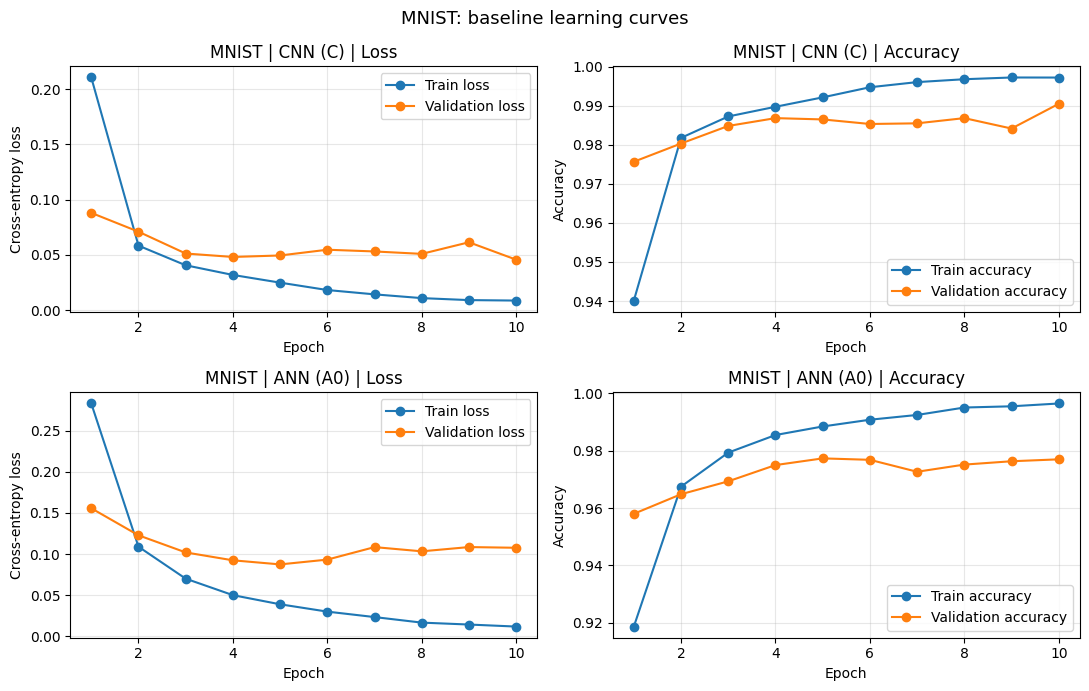

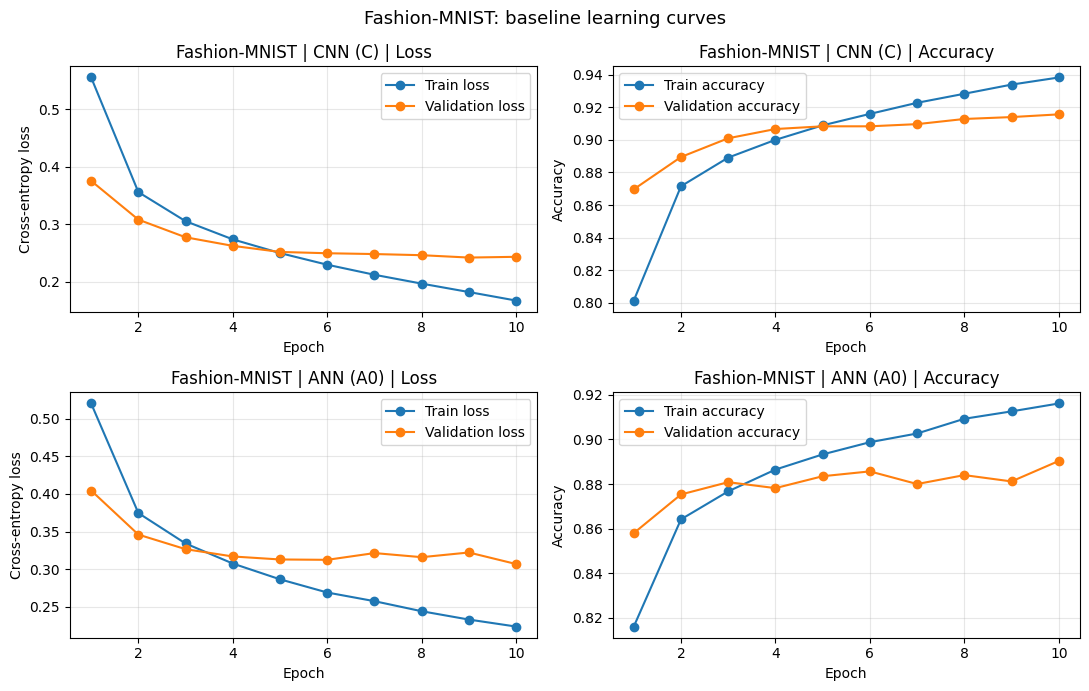

In [ ]:
# YOUR CODE HERE — learning-curve plots
for name in histories:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))

    for row, key in enumerate(["C", "A0"]):
        h = histories[name][key].history
        epochs_range = range(1, len(h["loss"]) + 1)
        model_label = "CNN (C)" if key == "C" else "ANN (A0)"

        # left: loss
        ax = axes[row, 0]
        ax.plot(epochs_range, h["loss"], marker="o", label="Train loss")
        ax.plot(epochs_range, h["val_loss"], marker="o", label="Validation loss")
        ax.set_title(f"{name} | {model_label} | Loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Cross-entropy loss")
        ax.legend()
        ax.grid(alpha=0.3)

        # right: accuracy
        ax = axes[row, 1]
        ax.plot(epochs_range, h["accuracy"], marker="o", label="Train accuracy")
        ax.plot(epochs_range, h["val_accuracy"], marker="o", label="Validation accuracy")
        ax.set_title(f"{name} | {model_label} | Accuracy")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(f"{name}: baseline learning curves", fontsize=13)
    plt.tight_layout()
    plt.show()

**Training and Learning-Curve Observations**

##Observation 1:

An epoch is one full pass over the training set,

The batch size is the number of images per weight update (128, so 422 updates per epoch),

the learning rate is the step size of each update (0.001 with Adam), and

Overfitting is when a model fits the training data well but does worse on unseen data, shown by training loss still falling while validation loss stops improving or rises.

##Observation 2:
I see no underfitting, since training accuracy is high and still rising for all four models. The clearest overfitting is the ANN on MNIST: its training loss keeps falling, but its validation loss reaches a minimum around epoch 5 and then rises to 0.1273, and its train-validation accuracy gap is 1.90 points versus 0.83 for the CNN. On Fashion-MNIST both models show milder overfitting, where validation loss flattens (CNN 0.2440, ANN 0.3145) while training loss keeps falling.

##Observation 3:
The CNN teacher must be trained before distillation because the student learns by imitating the teacher’s output distribution, and an untrained teacher produces essentially random logits that carry no knowledge about the data. The teacher is then frozen and used only to generate soft targets.

##Observation 4:
The CNN is better on both validation sets: 0.9892 vs 0.9765 on MNIST (1.27 points higher) and 0.9160 vs 0.8887 on Fashion-MNIST (2.73 points higher). The gap is about twice as large on the harder dataset, and the CNN achieves this with slightly fewer parameters (225,034 vs 235,146). These are validation results from a single seed, so the final comparison will come from the test set.

In [ ]:
for name in histories:
    for key in ["C", "A0"]:
        h = histories[name][key].history
        print(f"{name:14s} {key:3s} | train acc {h['accuracy'][-1]:.4f} "
              f"| val acc {h['val_accuracy'][-1]:.4f} "
              f"| val loss {h['val_loss'][-1]:.4f}")

MNIST          C   | train acc 0.9972 | val acc 0.9905 | val loss 0.0457
MNIST          A0  | train acc 0.9965 | val acc 0.9770 | val loss 0.1076
Fashion-MNIST  C   | train acc 0.9383 | val acc 0.9157 | val loss 0.2431
Fashion-MNIST  A0  | train acc 0.9161 | val acc 0.8903 | val loss 0.3068


## 5. Data Augmentation

Data augmentation creates label-preserving variations of training images. It can improve generalization by exposing a model to a wider range of image appearances, but transformations that are too strong may remove class-defining information.

Four transformations are implemented below. They are applied to training images only; validation and test images remain unchanged.

In [ ]:
from scipy.ndimage import shift, rotate, zoom, gaussian_filter, map_coordinates

MAX_SHIFT = 2.0   # maximum shift in pixels, in each direction
MAX_ANGLE = 10.0   # maximum rotation in degrees, in each direction
MIN_SCALE, MAX_SCALE = 0.9, 1.1 # zoom factor range
ELASTIC_ALPHA = 20.0   # displacement strength (scales the field)
ELASTIC_SIGMA = 4.0    # smoothing of the field (Gaussian std, in pixels)

def random_shift(image, rng):
    """Return shifted 28x28 image."""
    # YOUR CODE HERE
    dy, dx = rng.uniform(-MAX_SHIFT, MAX_SHIFT, size=2)
    #Draws two random numbers between −2 and +2.They are floats,shifts like 1.37 pixels are possible.
    return shift(image, shift=(dy, dx), order=1, mode="constant", cval=0.0)


def random_rotate(image, rng):
    """Return rotated 28x28 image."""
    # YOUR CODE HERE
    angle = rng.uniform(-MAX_ANGLE, MAX_ANGLE)
    return rotate(image, angle, reshape=False, order=1, mode="constant", cval=0.0)

def random_scale(image, rng):
    """Return scaled 28x28 image."""
    # YOUR CODE HERE
    n = image.shape[0]                               # 28
    factor = rng.uniform(MIN_SCALE, MAX_SCALE)
    zoomed = zoom(image, factor, order=1, mode="constant", cval=0.0)
    size = zoomed.shape[0]                           # new height = new width

    if size >= n:                                    # zoomed in: crop the center
        start = (size - n) // 2
        return zoomed[start:start + n, start:start + n]

    out = np.zeros_like(image)                       # zoomed out: black canvas
    start = (n - size) // 2
    out[start:start + size, start:start + size] = zoomed
    return out

def elastic_distort(image, rng):
    """Return elastically distorted 28x28 image using smooth displacement fields."""
    # YOUR CODE HERE
    n = image.shape[0]

    # 1) random displacement fields for rows (dy) and columns (dx)
    dx = gaussian_filter(rng.uniform(-1, 1, (n, n)), ELASTIC_SIGMA,
                         mode="constant", cval=0.0) * ELASTIC_ALPHA
    dy = gaussian_filter(rng.uniform(-1, 1, (n, n)), ELASTIC_SIGMA,
                         mode="constant", cval=0.0) * ELASTIC_ALPHA

    # 2) coordinate grid: y[i,j] = i, x[i,j] = j
    y, x = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")

    # 3) look up each output pixel at its displaced position
    return map_coordinates(image, [y + dy, x + dx],
                           order=1, mode="constant", cval=0.0)

def augment_image(image, rng):
    """Apply the four requested transformations; preserve (28,28,1)."""
    # YOUR CODE HERE
    img = image.squeeze()                 # (28,28,1) -> (28,28)
    img = random_rotate(img, rng)
    img = random_scale(img, rng)
    img = elastic_distort(img, rng)
    img = random_shift(img, rng)
    img = np.clip(img, 0.0, 1.0).astype("float32")
    return img[..., np.newaxis]           # back to (28,28,1)

### Visual Validation of Augmentations

Five original training images from each dataset are compared with augmented versions. The checks verify output shape, finite values, valid pixel range, and that the transformed examples remain associated with their original labels.

Magnitudes used: shift ± 2.0 px | rotation ± 10.0 deg | scale 0.9 to 1.1 | elastic alpha = 20.0 , sigma = 4.0


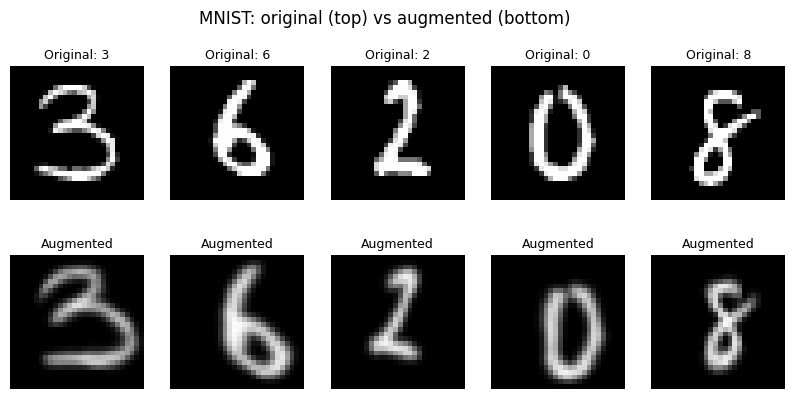

MNIST - all checks passed


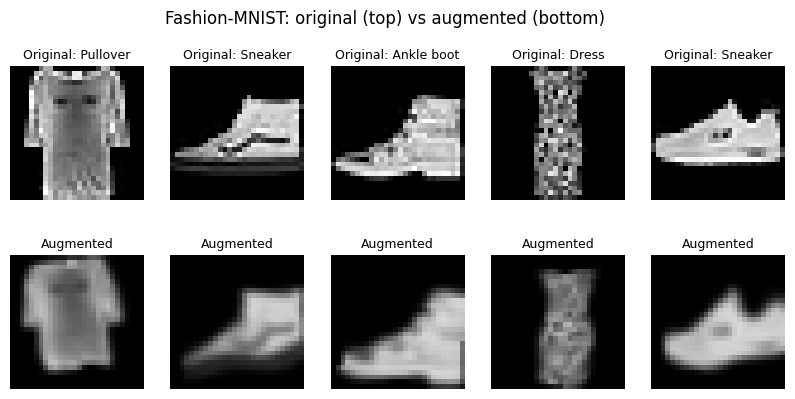

Fashion-MNIST - all checks passed


In [ ]:
# YOUR CODE HERE — augmentation sanity checks and original/augmented grids
rng = np.random.default_rng(SEED)

print("Magnitudes used: shift ±", MAX_SHIFT, "px | rotation ±", MAX_ANGLE,
      "deg | scale", MIN_SCALE, "to", MAX_SCALE,
      "| elastic alpha =", ELASTIC_ALPHA, ", sigma =", ELASTIC_SIGMA)

for name, d in datasets.items():
    x = d["x_train"]
    y = d["y_train"]
    idx = rng.choice(len(x), size=5, replace=False)     # 5 random training images

    plt.figure(figsize=(10, 4.5))
    for k, i in enumerate(idx):
        original = x[i]
        augmented = augment_image(original, rng)

        # sanity checks
        assert augmented.shape == (28, 28, 1)
        assert np.isfinite(augmented).all()
        assert augmented.min() >= 0 and augmented.max() <= 1

        # top row: original
        plt.subplot(2, 5, k + 1)
        plt.imshow(original.squeeze(), cmap="gray", vmin=0, vmax=1)
        plt.title("Original: " + class_names[name][y[i]], fontsize=9)
        plt.axis("off")

        # bottom row: augmented
        plt.subplot(2, 5, k + 6)
        plt.imshow(augmented.squeeze(), cmap="gray", vmin=0, vmax=1)
        plt.title("Augmented", fontsize=9)
        plt.axis("off")

    plt.suptitle(name + ": original (top) vs augmented (bottom)")
    plt.show()
    print(name, "- all checks passed")

### Augmentation Analysis

##Observation 1:

The shift moves the object up to 2 pixels horizontally and vertically, the rotation turns it by up to ±10°, the scaling enlarges or shrinks it by a factor of 0.9 to 1.1 (cropped or padded back to 28×28), and the elastic distortion displaces pixels by a smooth random field so strokes bend like a rubber sheet.

##Observation 2:

Augmentation is only for training data because validation and test sets must measure performance on real, unmodified images. Augmenting them would change what is being measured, and random transformations would make the scores differ from run to run.

##Observation 3:

An elastic distortion builds random displacement fields, smooths them with a Gaussian filter, scales them by alpha, and samples the image at the displaced coordinates. Smoothing (sigma = 4 here) makes neighbouring pixels move together, so strokes bend instead of tearing. With a tiny sigma the warp becomes noisy and jagged, and with a very large sigma it turns into almost a plain shift.

##Observation 4:

A strong rotation can change a label: a 6 turned by about 180° looks like a 9. For clothing, a strong zoom-in or large shift could crop away the sleeves that separate a pullover or shirt from a T-shirt.

##Answer 05:

In my grids all five MNIST digits (3, 6, 2, 0, 8) are still clearly the same digit after augmentation, with only small tilts and wobbles. On Fashion-MNIST the shapes are mostly preserved, but fine texture is blurred, the ankle boot and a sneaker are partly cut off at the right edge, and the pullover loses sleeve detail and looks closer to a T-shirt. So my strengths preserve MNIST labels well, while Fashion-MNIST is more fragile. The augmented images are also blurrier than the originals because several interpolation steps are stacked.

## 6. ANN with Data Augmentation (A1)

A1 is a fresh ANN with the same architecture and training budget as A0. Its training pipeline applies the augmentation transformations to training batches, while validation data remain unaugmented.


The batch inspection below checks image and label shapes, pixel ranges, and label alignment before training.

In [ ]:
def make_augmented_training_data(x_train, y_train, batch_size=BATCH_SIZE):
    """Return a batched iterable/dataset yielding augmented images and original labels."""
    # YOUR CODE HERE
    rng = np.random.default_rng(SEED)
    n = len(x_train)

    def generator():
        order = rng.permutation(n)                      # new shuffle every epoch
        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]
            xb = np.stack([augment_image(x_train[i], rng) for i in idx])
            yield xb, y_train[idx]                      # labels untouched

    return tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(None,), dtype=tf.int64),
        ),
    ).prefetch(tf.data.AUTOTUNE)



# YOUR CODE HERE — train A1 on MNIST and Fashion-MNIST
print(models["MNIST"].keys(), models["Fashion-MNIST"].keys())   # expect C and A0 in both
# Save model and history under key "A1"

dict_keys(['C', 'A0']) dict_keys(['C', 'A0'])


MNIST batch images: (128, 28, 28, 1) float32 | labels: (128,) int64


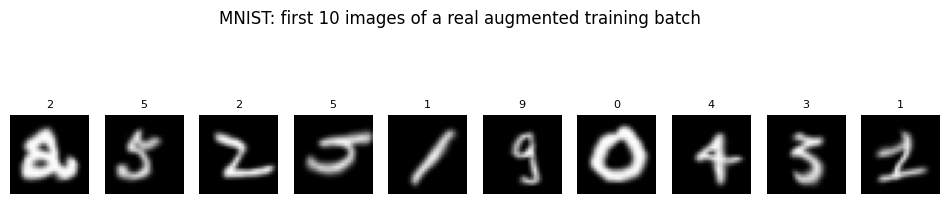

Fashion-MNIST batch images: (128, 28, 28, 1) float32 | labels: (128,) int64


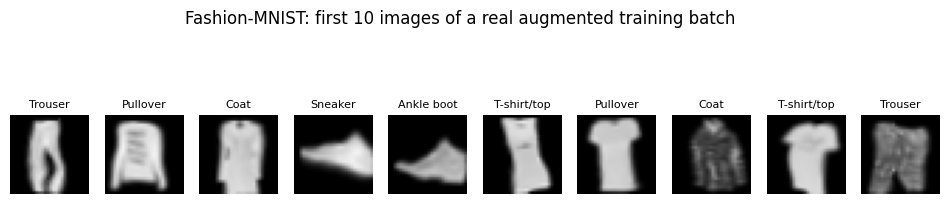

In [ ]:
for name, d in datasets.items():
    aug_ds = make_augmented_training_data(d["x_train"], d["y_train"])
    for xb, yb in aug_ds.take(1):
        xb, yb = xb.numpy(), yb.numpy()

    print(name, "batch images:", xb.shape, xb.dtype, "| labels:", yb.shape, yb.dtype)
    assert xb.shape == (BATCH_SIZE, 28, 28, 1)
    assert yb.shape == (BATCH_SIZE,)
    assert len(xb) == len(yb)
    assert np.isfinite(xb).all() and xb.min() >= 0 and xb.max() <= 1

    plt.figure(figsize=(12, 3))
    for k in range(10):
        plt.subplot(1, 10, k + 1)
        plt.imshow(xb[k].squeeze(), cmap="gray", vmin=0, vmax=1)
        plt.title(class_names[name][yb[k]], fontsize=8)
        plt.axis("off")
    plt.suptitle(name + ": first 10 images of a real augmented training batch")
    plt.show()

In [ ]:
for name, d in datasets.items():
    aug_ds = make_augmented_training_data(d["x_train"], d["y_train"])
    for xb, yb in aug_ds.take(1):
        xb, yb = xb.numpy(), yb.numpy()

    orig = d["x_train"].reshape(len(d["x_train"]), -1)
    orig = orig / np.linalg.norm(orig, axis=1, keepdims=True)
    batch = xb.reshape(len(xb), -1)
    batch = batch / np.linalg.norm(batch, axis=1, keepdims=True)

    nearest = (batch @ orig.T).argmax(axis=1)       # most similar original image
    agree = (d["y_train"][nearest] == yb).mean()
    print(f"{name}: label agreement with nearest original = {agree:.2f}")

MNIST: label agreement with nearest original = 0.79
Fashion-MNIST: label agreement with nearest original = 0.58


In [ ]:
import time

for name, d in datasets.items():
    print(f"\n--- Training A1 (ANN + augmentation) on {name} ---")
    tf.keras.utils.set_random_seed(SEED)              # same start as A0
    model = build_ann()                               # fresh ANN, same architecture
    aug_ds = make_augmented_training_data(d["x_train"], d["y_train"])

    start = time.time()
    history = train_supervised(model, aug_ds, None, d["x_val"], d["y_val"],
                               batch_size=None)       # the dataset already batches
    print(f"A1 training time on {name}: {time.time() - start:.0f} s")

    models[name]["A1"] = model
    histories[name]["A1"] = history

# quick A0 vs A1 summary (final epoch)
for name in histories:
    for key in ["A0", "A1"]:
        h = histories[name][key].history
        print(f"{name:14s} {key:3s} | train acc {h['accuracy'][-1]:.4f} "
              f"| val acc {h['val_accuracy'][-1]:.4f} "
              f"| val loss {h['val_loss'][-1]:.4f}")
    diff = (histories[name]["A1"].history["val_accuracy"][-1]
            - histories[name]["A0"].history["val_accuracy"][-1]) * 100
    print(f"{name}: A1 minus A0 validation accuracy = {diff:+.2f} points")


--- Training A1 (ANN + augmentation) on MNIST ---
Epoch 1/10
422/422 - 57s - 135ms/step - accuracy: 0.7974 - loss: 0.6561 - val_accuracy: 0.9468 - val_loss: 0.1781
Epoch 2/10
422/422 - 55s - 130ms/step - accuracy: 0.9068 - loss: 0.3048 - val_accuracy: 0.9583 - val_loss: 0.1325
Epoch 3/10
422/422 - 58s - 138ms/step - accuracy: 0.9234 - loss: 0.2483 - val_accuracy: 0.9700 - val_loss: 0.1034
Epoch 4/10
422/422 - 56s - 133ms/step - accuracy: 0.9353 - loss: 0.2087 - val_accuracy: 0.9730 - val_loss: 0.0918
Epoch 5/10
422/422 - 57s - 134ms/step - accuracy: 0.9395 - loss: 0.1952 - val_accuracy: 0.9702 - val_loss: 0.0998
Epoch 6/10
422/422 - 58s - 137ms/step - accuracy: 0.9436 - loss: 0.1820 - val_accuracy: 0.9717 - val_loss: 0.0959
Epoch 7/10
422/422 - 57s - 135ms/step - accuracy: 0.9473 - loss: 0.1699 - val_accuracy: 0.9702 - val_loss: 0.0922
Epoch 8/10
422/422 - 57s - 135ms/step - accuracy: 0.9516 - loss: 0.1591 - val_accuracy: 0.9757 - val_loss: 0.0801
Epoch 9/10
422/422 - 57s - 135ms/step

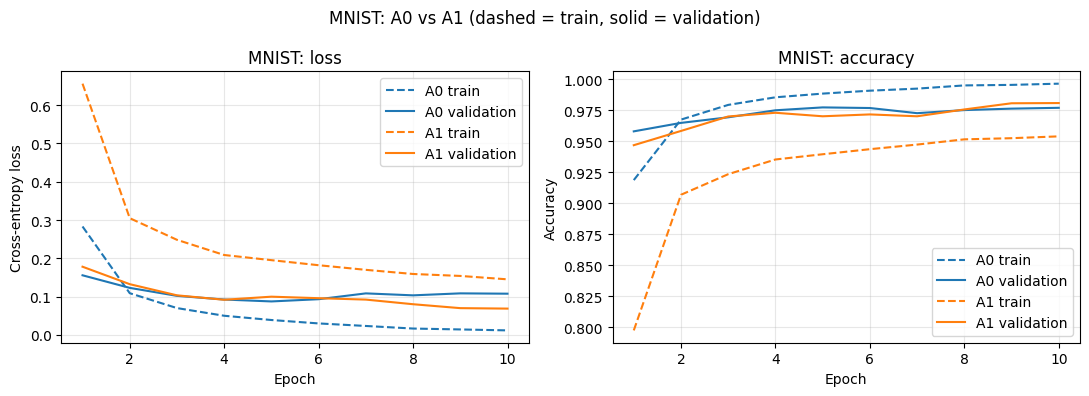

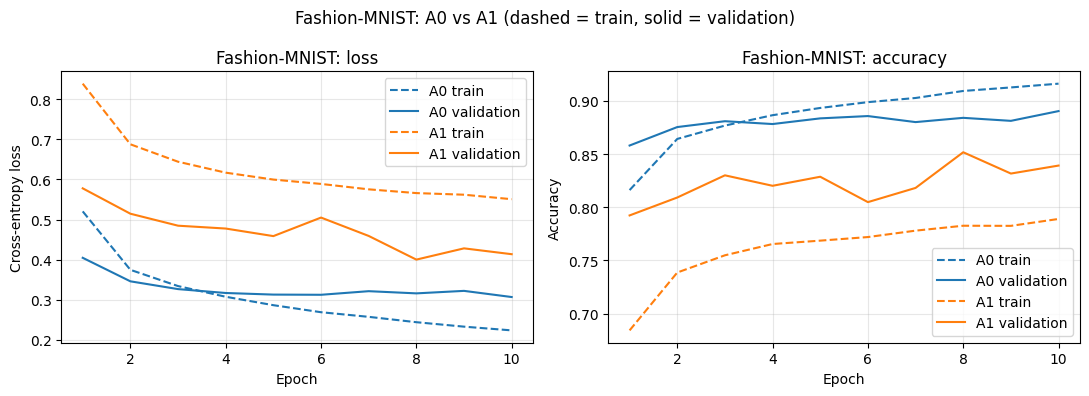

In [ ]:
for name in histories:
    plt.figure(figsize=(11, 4))

    for key, color in [("A0", "tab:blue"), ("A1", "tab:orange")]:
        h = histories[name][key].history
        epochs = range(1, len(h["loss"]) + 1)

        plt.subplot(1, 2, 1)                                   # left panel: loss
        plt.plot(epochs, h["loss"], "--", color=color, label=key + " train")
        plt.plot(epochs, h["val_loss"], "-", color=color, label=key + " validation")

        plt.subplot(1, 2, 2)                                   # right panel: accuracy
        plt.plot(epochs, h["accuracy"], "--", color=color, label=key + " train")
        plt.plot(epochs, h["val_accuracy"], "-", color=color, label=key + " validation")

    plt.subplot(1, 2, 1)
    plt.title(name + ": loss")
    plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.legend(); plt.grid(alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.title(name + ": accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(alpha=0.3)

    plt.suptitle(name + ": A0 vs A1 (dashed = train, solid = validation)")
    plt.tight_layout()
    plt.show()

### A1 Results and Interpretation
Observation 2:

On MNIST, A1 reached a validation accuracy of 0.9808 vs 0.9770 for A0 (+0.38 points) and a lower validation loss (0.0687 vs 0.1076), and A0’s validation loss rose after about epoch 5 while A1’s mostly kept falling. A1 trailed A0 for most of training and only overtook it around epochs 8 to 10. On Fashion-MNIST augmentation did not help: validation accuracy fell from 0.8903 to 0.8392 (−5.12 points) and validation loss rose from 0.3068 to 0.4136, so the two datasets did not benefit equally. A1’s Fashion-MNIST training accuracy was only 0.789 and still rising, which suggests underfitting, possibly because blur and edge cropping from the stacked transformations remove the texture detail Fashion-MNIST relies on and 10 epochs is too short for the harder data (a hypothesis I did not test). These are single-run results, so the small MNIST gain should be read as suggestive, not conclusive.

Observation 3:

Augmentation adds CPU work for every image in every epoch: A1 took about 55 to 60 seconds per epoch (roughly 570 to 600 seconds per dataset) compared with about 3 to 6 seconds per epoch (35 to 40 seconds total) for A0, while adding no extra model parameters.

## 7. Knowledge Distillation (A2)

Knowledge distillation trains a student model using the outputs of a previously trained teacher. The teacher's softened probability distribution contains information about relationships between classes, beyond the single correct hard label.

Let teacher logits be `z_t`, student logits be `z_s`, and temperature be `T > 0`:

$$
p_t=\operatorname{softmax}(z_t/T),\qquad p_s=\operatorname{softmax}(z_s/T).
$$

Use the following loss:

$$
L = \alpha L_{CE}(y,z_s) + (1-\alpha)T^2 D_{KL}(p_t\|p_s).
$$

`L_CE` uses **hard labels and unscaled student logits**. `D_KL` compares softened teacher and student probabilities. The teacher must be **frozen**; update only student parameters. Explain your choices of `T` and `alpha`.

The cross-entropy term uses hard labels and unscaled student logits. The KL-divergence term compares softened teacher and student probabilities. The teacher remains frozen, so only student parameters are updated. The chosen values of `T` and `alpha` are defined in the experiment settings.

In [ ]:
from types import SimpleNamespace
def distillation_loss(y_true, teacher_logits, student_logits,
                      temperature=TEMPERATURE, alpha=ALPHA):
    """Return total loss, hard-label CE, and temperature-scaled KL loss."""
    teacher_logits = tf.stop_gradient(teacher_logits)      # teacher is never updated

    # 1) hard-label cross-entropy on UNSCALED student logits
    ce = tf.reduce_mean(
        tf.nn.sparse_softmax_cross_entropy_with_logits(labels=y_true,
                                                       logits=student_logits))

    # 2) KL divergence between softened teacher and student distributions
    p_t = tf.nn.softmax(teacher_logits / temperature)
    log_p_t = tf.nn.log_softmax(teacher_logits / temperature)
    log_p_s = tf.nn.log_softmax(student_logits / temperature)
    kl = tf.reduce_mean(tf.reduce_sum(p_t * (log_p_t - log_p_s), axis=-1))
    kl_scaled = (temperature ** 2) * kl

    # 3) combine
    total = alpha * ce + (1.0 - alpha) * kl_scaled
    return total, ce, kl_scaled

def train_distilled_student(student, teacher, train_data, x_val, y_val,
                            epochs=EPOCHS):
    """Train only student weights; return a history with loss and accuracy.
    train_data should yield (images, integer_labels) batches.
    """
    teacher.trainable = False                      # freeze the teacher
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    history = {"loss": [], "ce_loss": [], "kl_loss": [], "accuracy": [],
               "val_loss": [], "val_accuracy": []}

    for epoch in range(1, epochs + 1):
        losses, ces, kls, accs = [], [], [], []

        for xb, yb in train_data:
            teacher_logits = teacher(xb, training=False)        # teacher only predicts

            with tf.GradientTape() as tape:
                student_logits = student(xb, training=True)
                total, ce, kl = distillation_loss(yb, teacher_logits, student_logits)

            grads = tape.gradient(total, student.trainable_variables)
            optimizer.apply_gradients(zip(grads, student.trainable_variables))

            predicted = tf.argmax(student_logits, axis=1)
            acc = tf.reduce_mean(tf.cast(tf.equal(predicted, yb), tf.float32))
            losses.append(float(total)); ces.append(float(ce))
            kls.append(float(kl));       accs.append(float(acc))

        # validation: forward pass only, no weight updates
        val_logits = student.predict(x_val, batch_size=1000, verbose=0)
        val_loss = float(tf.reduce_mean(
            tf.nn.sparse_softmax_cross_entropy_with_logits(labels=y_val, logits=val_logits)))
        val_acc = float(np.mean(np.argmax(val_logits, axis=1) == y_val))

        history["loss"].append(np.mean(losses))
        history["ce_loss"].append(np.mean(ces))
        history["kl_loss"].append(np.mean(kls))
        history["accuracy"].append(np.mean(accs))
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        print(f"Epoch {epoch}/{epochs} - loss: {np.mean(losses):.4f} - "
              f"train acc: {np.mean(accs):.4f} - val loss: {val_loss:.4f} - val acc: {val_acc:.4f}")

    result = tf.keras.callbacks.History()      # behaves like a normal Keras history
    result.history = history
    return result
# YOUR CODE HERE — train A2 on BOTH datasets, using the matching frozen CNN

In [ ]:
   print(models["MNIST"].keys(), models["Fashion-MNIST"].keys())

dict_keys(['C', 'A0', 'A1']) dict_keys(['C', 'A0', 'A1'])


In [ ]:
import time

for name, d in datasets.items():
    print("Training A2 on", name)

    tf.keras.utils.set_random_seed(SEED)       # same random start as A0 and A1
    student = build_ann()                      # brand new ANN
    teacher = models[name]["C"]                # the trained CNN of this dataset

    # how good is the teacher? (validation data only)
    teacher_val_acc = teacher.evaluate(d["x_val"], d["y_val"], verbose=0)[1]
    print("Teacher (CNN) validation accuracy:", round(teacher_val_acc, 4))

    # save the teacher's weights so we can prove they don't change
    teacher_before = teacher.get_weights()

    # normal (un-augmented) training images, shuffled and batched
    train_data = tf.data.Dataset.from_tensor_slices((d["x_train"], d["y_train"]))
    train_data = train_data.shuffle(len(d["x_train"]), seed=SEED).batch(BATCH_SIZE)

    # train the student, and time it
    start = time.time()
    history = train_distilled_student(student, teacher, train_data,
                                      d["x_val"], d["y_val"])
    print("Time taken (seconds):", round(time.time() - start))

    # check the teacher was not changed
    teacher_after = teacher.get_weights()
    same = all(np.array_equal(a, b) for a, b in zip(teacher_before, teacher_after))
    print("Teacher weights unchanged:", same)

    # save
    models[name]["A2"] = student
    histories[name]["A2"] = history

Training A2 on MNIST
Teacher (CNN) validation accuracy: 0.9905
Epoch 1/10 - loss: 1.6118 - train acc: 0.9058 - val loss: 0.2400 - val acc: 0.9505
Epoch 2/10 - loss: 0.5610 - train acc: 0.9626 - val loss: 0.1739 - val acc: 0.9632
Epoch 3/10 - loss: 0.3631 - train acc: 0.9752 - val loss: 0.1379 - val acc: 0.9692
Epoch 4/10 - loss: 0.2641 - train acc: 0.9830 - val loss: 0.1261 - val acc: 0.9755
Epoch 5/10 - loss: 0.2039 - train acc: 0.9870 - val loss: 0.1064 - val acc: 0.9768
Epoch 6/10 - loss: 0.1637 - train acc: 0.9908 - val loss: 0.0979 - val acc: 0.9802
Epoch 7/10 - loss: 0.1337 - train acc: 0.9933 - val loss: 0.0985 - val acc: 0.9808
Epoch 8/10 - loss: 0.1162 - train acc: 0.9943 - val loss: 0.0838 - val acc: 0.9838
Epoch 9/10 - loss: 0.1018 - train acc: 0.9957 - val loss: 0.0938 - val acc: 0.9808
Epoch 10/10 - loss: 0.0878 - train acc: 0.9970 - val loss: 0.0908 - val acc: 0.9805
Time taken (seconds): 693
Teacher weights unchanged: True
Training A2 on Fashion-MNIST
Teacher (CNN) valid

In [ ]:
for name in histories:
    a0 = histories[name]["A0"].history["val_accuracy"][-1]
    a1 = histories[name]["A1"].history["val_accuracy"][-1]
    a2 = histories[name]["A2"].history["val_accuracy"][-1]
    print(name, "| A0:", round(a0, 4), "| A1:", round(a1, 4), "| A2:", round(a2, 4),
          "| A2 minus A0 (points):", round((a2 - a0) * 100, 2))

MNIST | A0: 0.977 | A1: 0.9808 | A2: 0.9805 | A2 minus A0 (points): 0.35
Fashion-MNIST | A0: 0.8903 | A1: 0.8392 | A2: 0.902 | A2 minus A0 (points): 1.17


### Inspecting Teacher Predictions

For validation examples from each dataset, the notebook compares the teacher's top-three class probabilities at temperature `T = 1` with its softened probabilities at the selected distillation temperature. Validation data are used for inspection, not gradient updates.

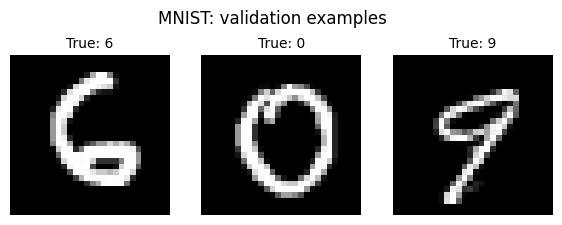

===== MNIST =====
Example 1 | true class: 6
   T=1 top 3: 6: 1.000 | 5: 0.000 | 8: 0.000
   T=3 top 3: 6: 0.983 | 5: 0.011 | 8: 0.005
Example 2 | true class: 0
   T=1 top 3: 0: 1.000 | 9: 0.000 | 8: 0.000
   T=3 top 3: 0: 0.991 | 9: 0.003 | 8: 0.003
Example 3 | true class: 9
   T=1 top 3: 9: 1.000 | 8: 0.000 | 7: 0.000
   T=3 top 3: 9: 0.948 | 8: 0.027 | 7: 0.011


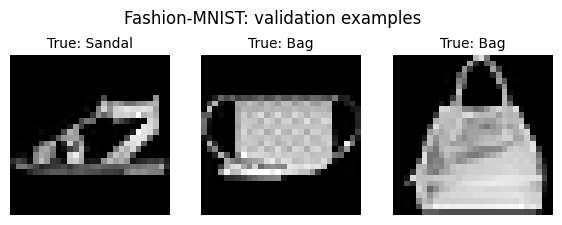

===== Fashion-MNIST =====
Example 1 | true class: Sandal
   T=1 top 3: Sandal: 1.000 | Bag: 0.000 | T-shirt/top: 0.000
   T=3 top 3: Sandal: 0.995 | Bag: 0.003 | T-shirt/top: 0.001
Example 2 | true class: Bag
   T=1 top 3: Bag: 0.997 | T-shirt/top: 0.002 | Sandal: 0.000
   T=3 top 3: Bag: 0.710 | T-shirt/top: 0.085 | Sandal: 0.050
Example 3 | true class: Bag
   T=1 top 3: Bag: 1.000 | Sneaker: 0.000 | Dress: 0.000
   T=3 top 3: Bag: 0.984 | Sneaker: 0.006 | Dress: 0.004


In [ ]:
# YOUR CODE HERE — teacher probability inspection (validation data only)
def top3_text(probs, names):
    best = np.argsort(probs)[::-1][:3]          # positions of the 3 biggest probabilities
    return " | ".join(f"{names[c]}: {probs[c]:.3f}" for c in best)

pick_rng = np.random.default_rng(SEED)

for name, d in datasets.items():
    teacher = models[name]["C"]
    names = class_names[name]

    # pick 3 random VALIDATION images (no test data)
    idx = pick_rng.choice(len(d["x_val"]), size=3, replace=False)
    images = d["x_val"][idx]
    labels = d["y_val"][idx]

    # teacher logits -> probabilities at T=1 and at the selected temperature
    logits = teacher.predict(images, verbose=0)
    probs_t1 = tf.nn.softmax(logits / 1.0).numpy()
    probs_tT = tf.nn.softmax(logits / TEMPERATURE).numpy()

    # show the images
    plt.figure(figsize=(7, 2.6))
    for k in range(3):
        plt.subplot(1, 3, k + 1)
        plt.imshow(images[k].squeeze(), cmap="gray", vmin=0, vmax=1)
        plt.title("True: " + names[labels[k]], fontsize=10)
        plt.axis("off")
    plt.suptitle(name + ": validation examples")
    plt.show()

    # print true class and top-3 probabilities
    print("=====", name, "=====")
    for k in range(3):
        print("Example", k + 1, "| true class:", names[labels[k]])
        print("   T=1 top 3:", top3_text(probs_t1[k], names))
        print(f"   T={TEMPERATURE:g} top 3:", top3_text(probs_tT[k], names))

### Distillation Analysis

Answer 01;
A hard label is a one-hot target that only says which class is correct, while a soft label is the teacher’s full probability distribution, which also shows how similar the other classes look.

Answer  02:

Raising the temperature divides the logits by T, so the distribution flattens: the top probability falls and the small ones rise, but the ranking stays the same. In my Fashion-MNIST bag example the teacher gave Bag 0.997, T-shirt/top 0.002 and Sandal 0.000 at T=1, but Bag 0.710, T-shirt/top 0.085 and Sandal 0.050 at T=3, while on easy images like the MNIST 9 the change is smaller (9: 1.000 to 0.948, 8: 0.000 to 0.027).

Answer  03:

KL divergence measures how far the student’s distribution is from the teacher’s, and the T² factor restores the gradient size that softening shrinks by about 1/T².
The teacher stays frozen so it remains a fixed target, and I checked that its weights were identical before and after training.

Answer  04:

Alpha weights the hard-label loss against the KL term, so at alpha = 1 the teacher has no effect and training is ordinary supervised learning.

Answer  05:

If the teacher is confidently wrong, the student learns that mistake, and the hard-label term (alpha above 0) is what partly corrects it.

## 8. Combined Training Strategy (A3)
A3 combines the augmented training pipeline with knowledge distillation. It is initialized as a new ANN rather than continuing from A1 or A2 weights.

For each augmented batch, the frozen CNN teacher and ANN student receive the same transformed images. This ensures that the distillation loss compares predictions for the same input. The architecture, temperature, distillation weight, and epoch budget match the A2 experiment.

In [ ]:
# YOUR CODE HERE — train fresh A3 student on BOTH datasets
# Reuse train_distilled_student with augmented batches, or justify a modification.
# Save models and histories under key "A3".
import time

for name, d in datasets.items():
    print("Training A3 on", name)

    tf.keras.utils.set_random_seed(SEED)       # same random start as A0, A1, A2
    student = build_ann()                      # brand new ANN, not A1 or A2
    teacher = models[name]["C"]                # the matching frozen CNN

    # save the teacher's weights so we can prove they don't change
    teacher_before = teacher.get_weights()

    # augmented training batches (images change, labels stay)
    aug_data = make_augmented_training_data(d["x_train"], d["y_train"])

    # train the student with the distillation loss on these batches
    start = time.time()
    history = train_distilled_student(student, teacher, aug_data,
                                      d["x_val"], d["y_val"])
    print("Time taken (seconds):", round(time.time() - start))

    # check the teacher was not changed
    teacher_after = teacher.get_weights()
    same = all(np.array_equal(a, b) for a, b in zip(teacher_before, teacher_after))
    print("Teacher weights unchanged:", same)

    # save
    models[name]["A3"] = student
    histories[name]["A3"] = history

Training A3 on MNIST
Epoch 1/10 - loss: 2.1599 - train acc: 0.7593 - val loss: 0.1658 - val acc: 0.9547
Epoch 2/10 - loss: 0.8426 - train acc: 0.8848 - val loss: 0.1183 - val acc: 0.9695
Epoch 3/10 - loss: 0.6430 - train acc: 0.9031 - val loss: 0.1042 - val acc: 0.9722
Epoch 4/10 - loss: 0.5380 - train acc: 0.9128 - val loss: 0.0950 - val acc: 0.9762
Epoch 5/10 - loss: 0.4798 - train acc: 0.9170 - val loss: 0.0880 - val acc: 0.9778
Epoch 6/10 - loss: 0.4425 - train acc: 0.9217 - val loss: 0.0899 - val acc: 0.9762
Epoch 7/10 - loss: 0.4100 - train acc: 0.9243 - val loss: 0.0823 - val acc: 0.9787
Epoch 8/10 - loss: 0.3851 - train acc: 0.9266 - val loss: 0.0741 - val acc: 0.9807
Epoch 9/10 - loss: 0.3724 - train acc: 0.9286 - val loss: 0.0774 - val acc: 0.9802
Epoch 10/10 - loss: 0.3531 - train acc: 0.9305 - val loss: 0.0665 - val acc: 0.9815
Time taken (seconds): 1152
Teacher weights unchanged: True
Training A3 on Fashion-MNIST
Epoch 1/10 - loss: 1.0549 - train acc: 0.6551 - val loss: 0.

### A3 Results and Interpretation

###Observation 1:
Augmentation and distillation can complement each other because they help in different ways: augmentation gives the ANN more varied images so it can’t just memorize, while distillation gives it richer targets, since the teacher’s soft probabilities show which classes look alike.

###Observation 2:

The teacher and student must see the same augmented image because the loss compares the student’s prediction with the teacher’s prediction for that exact image, and if they saw different versions the teacher’s soft label would describe a different picture.

###Observation 3:

A3 must start from scratch so it is a separate, fair experiment, because starting from A1 or A2 weights would mix in earlier training and we couldn’t tell what caused any difference.

###Observation 4:

One plausible reason A3 could perform worse than A1 or A2 is that the teacher was trained on clean images, so its soft labels for blurry, distorted images may be less reliable, and the harder task may be too much for a small ANN in 10 epochs; in my results on Fashion-MNIST, A3 (0.8605) ended below A2 (0.9020), though I did not test this explanation.

## 9. Model Evaluation and Error Analysis
After model development and configuration choices are complete, all five configurations are evaluated on the untouched test split for each dataset.

The evaluation reports accuracy, macro precision, macro recall, macro F1-score, and the CNN accuracy gap in percentage points:

`CNN_gap_pp = 100 × (CNN_accuracy − model_accuracy)`

A smaller positive gap means the ANN is closer to the CNN; a negative gap means the evaluated model outperformed the CNN. Classification reports are also generated for the best ANN variant on each dataset.

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report

def predict_classes(model, x):
    logits = model.predict(x, batch_size=1000, verbose=0)    # raw scores, shape (N, 10)
    return np.argmax(logits, axis=1)                         # class with the biggest score

def evaluate_model(model, x_test, y_test):
    """Return dict with accuracy, macro precision, macro recall, macro F1.
    Convert logits to predicted class IDs; use zero_division=0 where appropriate.
    """
    y_pred = predict_classes(model, x_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy, "precision_macro": precision,
            "recall_macro": recall, "f1_macro": f1}

# ---------- 1) evaluate all 10 models on the TEST set ----------
rows = []
for name, d in datasets.items():
    for key in ["C", "A0", "A1", "A2", "A3"]:
        scores = evaluate_model(models[name][key], d["x_test"], d["y_test"])
        rows.append({"Dataset": name,
                     "Model": key,
                     "Accuracy": scores["accuracy"],
                     "Precision_macro": scores["precision_macro"],
                     "Recall_macro": scores["recall_macro"],
                     "F1_macro": scores["f1_macro"]})

results_df = pd.DataFrame(rows)

# ---------- 2) CNN gap in percentage points ----------
results_df["CNN_gap_pp"] = 0.0
for name in datasets:
    mask = results_df["Dataset"] == name
    cnn_acc = results_df.loc[mask & (results_df["Model"] == "C"), "Accuracy"].iloc[0]
    results_df.loc[mask, "CNN_gap_pp"] = 100 * (cnn_acc - results_df.loc[mask, "Accuracy"])

print(results_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# ---------- 3) best ANN per dataset + classification report ----------
best_ann = {}
for name, d in datasets.items():
    anns = results_df[(results_df["Dataset"] == name) & (results_df["Model"] != "C")]
    best_key = anns.loc[anns["Accuracy"].idxmax(), "Model"]
    best_ann[name] = best_key

    print(f"\n===== {name}: best ANN = {best_key} =====")
    y_pred = predict_classes(models[name][best_key], d["x_test"])
    print(classification_report(d["y_test"], y_pred,
                                target_names=class_names[name],
                                digits=4, zero_division=0))

# YOUR CODE HERE — evaluate all 10 trained models and build results_df
# YOUR CODE HERE — compute CNN_gap_pp using the CNN of the SAME dataset
# YOUR CODE HERE — print classification reports for best ANN per dataset

      Dataset Model  Accuracy  Precision_macro  Recall_macro  F1_macro  CNN_gap_pp
        MNIST     C    0.9895           0.9894        0.9894    0.9894      0.0000
        MNIST    A0    0.9795           0.9793        0.9793    0.9793      1.0000
        MNIST    A1    0.9818           0.9816        0.9817    0.9816      0.7700
        MNIST    A2    0.9821           0.9820        0.9821    0.9820      0.7400
        MNIST    A3    0.9859           0.9859        0.9859    0.9858      0.3600
Fashion-MNIST     C    0.9064           0.9071        0.9064    0.9064      0.0000
Fashion-MNIST    A0    0.8779           0.8793        0.8779    0.8771      2.8500
Fashion-MNIST    A1    0.8303           0.8354        0.8303    0.8230      7.6100
Fashion-MNIST    A2    0.8883           0.8885        0.8883    0.8879      1.8100
Fashion-MNIST    A3    0.8443           0.8456        0.8443    0.8393      6.2100

===== MNIST: best ANN = A3 =====
              precision    recall  f1-score   support

### Results table

Display your complete **10-row** results table in the notebook. Make a grouped bar plot of test accuracy for all five configurations on both datasets, and a separate plot of the ANN-to-CNN accuracy gaps.

      Dataset Model  Accuracy  Precision_macro  Recall_macro  F1_macro  CNN_gap_pp
        MNIST     C    0.9895           0.9894        0.9894    0.9894      0.0000
        MNIST    A0    0.9795           0.9793        0.9793    0.9793      1.0000
        MNIST    A1    0.9818           0.9816        0.9817    0.9816      0.7700
        MNIST    A2    0.9821           0.9820        0.9821    0.9820      0.7400
        MNIST    A3    0.9859           0.9859        0.9859    0.9858      0.3600
Fashion-MNIST     C    0.9064           0.9071        0.9064    0.9064      0.0000
Fashion-MNIST    A0    0.8779           0.8793        0.8779    0.8771      2.8500
Fashion-MNIST    A1    0.8303           0.8354        0.8303    0.8230      7.6100
Fashion-MNIST    A2    0.8883           0.8885        0.8883    0.8879      1.8100
Fashion-MNIST    A3    0.8443           0.8456        0.8443    0.8393      6.2100


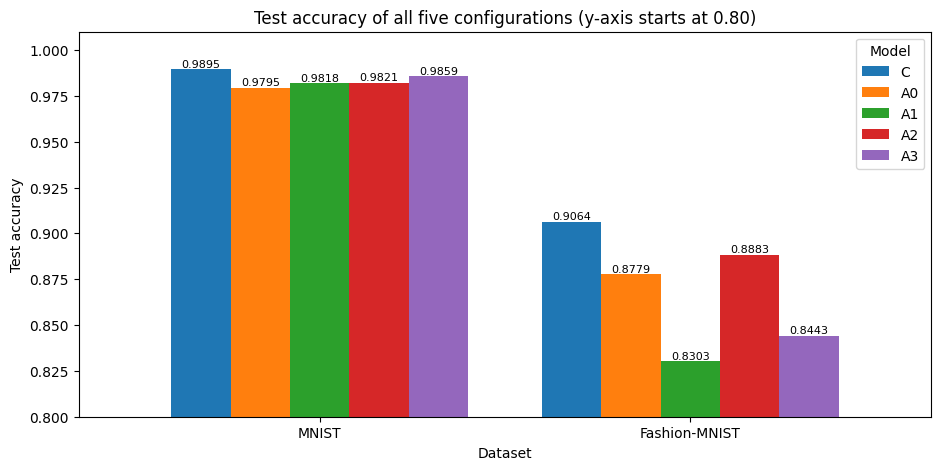

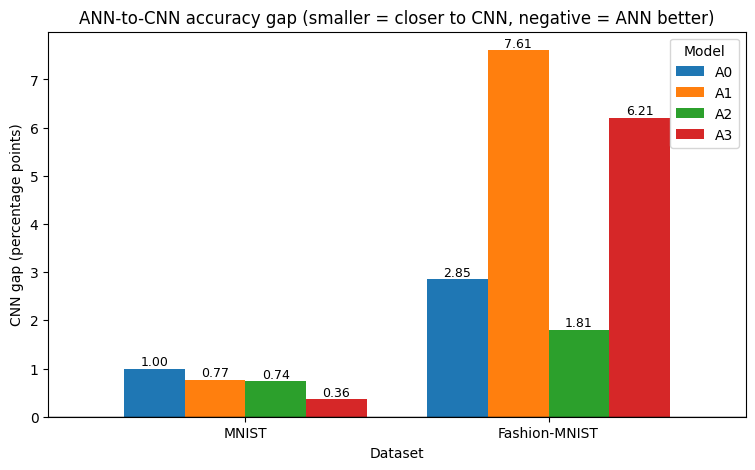

In [ ]:
# YOUR CODE HERE — formatted comparison table and TWO labeled plots
# ---------- table (4 decimals) ----------
print(results_df.to_string(index=False, float_format="{:.4f}".format))

# ---------- PLOT 1: test accuracy, all five models ----------
acc = results_df.pivot(index="Dataset", columns="Model", values="Accuracy")
acc = acc.loc[["MNIST", "Fashion-MNIST"], ["C", "A0", "A1", "A2", "A3"]]

ax = acc.plot(kind="bar", figsize=(11, 5), width=0.8, rot=0)
ax.set_ylim(0.80, 1.01)
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy of all five configurations (y-axis starts at 0.80)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", fontsize=8)
plt.show()

# ---------- PLOT 2: ANN-to-CNN gap ----------
gap = results_df.pivot(index="Dataset", columns="Model", values="CNN_gap_pp")
gap = gap.loc[["MNIST", "Fashion-MNIST"], ["A0", "A1", "A2", "A3"]]

ax = gap.plot(kind="bar", figsize=(9, 5), width=0.8, rot=0)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("CNN gap (percentage points)")
ax.set_title("ANN-to-CNN accuracy gap (smaller = closer to CNN, negative = ANN better)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9)
plt.show()

### Confusion Matrices and Misclassification Analysis

Confusion matrices are plotted for the CNN, baseline ANN, and best ANN variant on each dataset. Incorrectly classified test examples are also displayed for the best ANN, with their true and predicted labels. These examples are used for error analysis, not for further model tuning.

\n MNIST C - five most frequent confusions:
True 3 -> Predicted 5: 7
True 9 -> Predicted 4: 6
True 2 -> Predicted 7: 6
True 9 -> Predicted 8: 5
True 9 -> Predicted 5: 5
\n MNIST A0 - five most frequent confusions:
True 9 -> Predicted 4: 14
True 9 -> Predicted 8: 10
True 3 -> Predicted 8: 8
True 9 -> Predicted 5: 6
True 6 -> Predicted 8: 6
\n MNIST A3 - five most frequent confusions:
True 4 -> Predicted 9: 16
True 9 -> Predicted 7: 8
True 2 -> Predicted 7: 8
True 8 -> Predicted 5: 7
True 7 -> Predicted 2: 7


/tmp/ipykernel_28650/1031929187.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


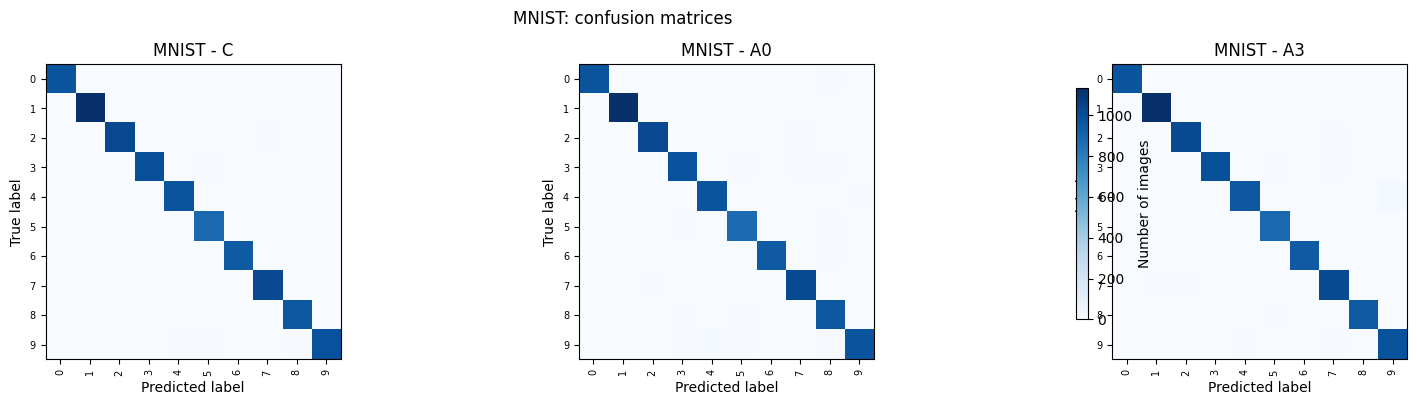

\nMNIST: five errors from best ANN (A3)


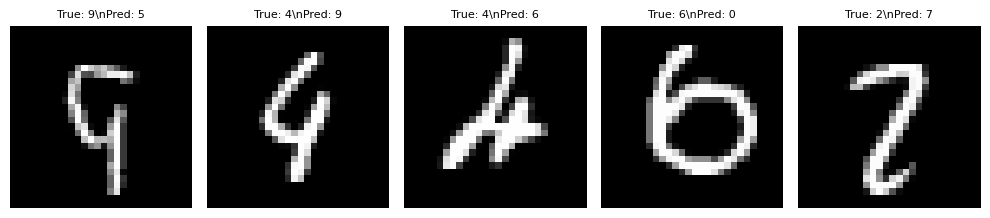

\n Fashion-MNIST C - five most frequent confusions:
True Shirt -> Predicted T-shirt/top: 111
True T-shirt/top -> Predicted Shirt: 97
True Pullover -> Predicted Shirt: 76
True Coat -> Predicted Pullover: 70
True Shirt -> Predicted Pullover: 62
\n Fashion-MNIST A0 - five most frequent confusions:
True Coat -> Predicted Pullover: 152
True Shirt -> Predicted T-shirt/top: 133
True T-shirt/top -> Predicted Shirt: 100
True Pullover -> Predicted Shirt: 86
True Coat -> Predicted Dress: 73
\n Fashion-MNIST A2 - five most frequent confusions:
True Shirt -> Predicted T-shirt/top: 129
True Pullover -> Predicted Coat: 116
True T-shirt/top -> Predicted Shirt: 97
True Pullover -> Predicted Shirt: 80
True Shirt -> Predicted Pullover: 75


/tmp/ipykernel_28650/1031929187.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


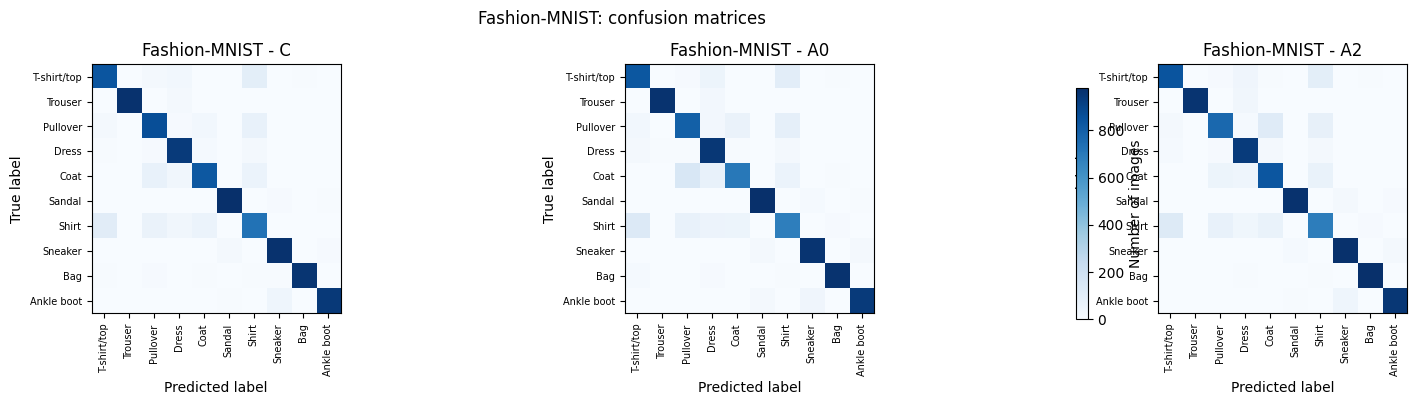

\nFashion-MNIST: five errors from best ANN (A2)


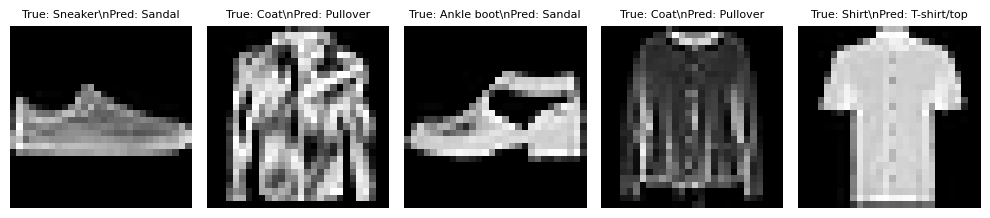

In [ ]:
# YOUR CODE HERE — confusion matrices and misclassified examples
# Confusion matrices for CNN, baseline ANN, and best ANN
from sklearn.metrics import confusion_matrix

for name, d in datasets.items():
    # Find the best ANN using test accuracy from the results table
    ann_rows = results_df[
        (results_df["Dataset"] == name) & (results_df["Model"] != "C")
    ]
    best_key = ann_rows.loc[ann_rows["Accuracy"].idxmax(), "Model"]
    model_keys = ["C", "A0", best_key]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, key in zip(axes, model_keys):
        y_pred = predict_classes(models[name][key], d["x_test"])
        cm = confusion_matrix(d["y_test"], y_pred)

        image = ax.imshow(cm, cmap="Blues")
        ax.set_title(name + " - " + key)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_xticks(range(10))
        ax.set_yticks(range(10))
        ax.set_xticklabels(class_names[name], rotation=90, fontsize=7)
        ax.set_yticklabels(class_names[name], fontsize=7)

        # Print the five most frequent incorrect class pairs
        cm_wrong = cm.copy()
        np.fill_diagonal(cm_wrong, 0)
        pairs = np.argsort(cm_wrong.ravel())[::-1][:5]
        print("\\n", name, key, "- five most frequent confusions:")
        for pos in pairs:
            true_id, pred_id = np.unravel_index(pos, cm_wrong.shape)
            if cm_wrong[true_id, pred_id] > 0:
                print(f"True {class_names[name][true_id]} -> "
                      f"Predicted {class_names[name][pred_id]}: "
                      f"{cm_wrong[true_id, pred_id]}")

    fig.colorbar(image, ax=axes, shrink=0.75, label="Number of images")
    fig.suptitle(name + ": confusion matrices")
    plt.tight_layout()
    plt.show()

    # Show five wrongly classified test images from the best ANN
    best_model = models[name][best_key]
    predictions = predict_classes(best_model, d["x_test"])
    wrong = np.where(predictions != d["y_test"])[0][:5]

    print(f"\\n{name}: five errors from best ANN ({best_key})")
    plt.figure(figsize=(10, 2.5))
    for j, idx in enumerate(wrong):
        plt.subplot(1, 5, j + 1)
        plt.imshow(d["x_test"][idx].squeeze(), cmap="gray")
        plt.title("True: " + class_names[name][d["y_test"][idx]] +
                  "\\nPred: " + class_names[name][predictions[idx]], fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


### Evaluation Metrics and Error Analysis
Accuracy is the proportion of all test images that the model classifies correctly. Precision measures, for a class, how many images predicted as that class actually belong to it, while recall measures how many of the actual images of that class the model correctly identifies. F1-score is the harmonic mean of precision and recall, balancing the two measures. Accuracy alone can hide weak performance on individual classes, especially when errors are concentrated in particular categories. Macro averaging calculates a metric separately for every class and then takes the unweighted average, so every class contributes equally. The CNN gaps for A0, A1, A2 and A3 are 1.00, 0.77, 0.74 and 0.36 percentage points on MNIST, and 2.85, 7.61, 1.81 and 6.21 points on Fashion-MNIST. In the best ANN confusion matrices, MNIST A3 most often confuses 4 as 9 (16 images), while Fashion-MNIST A2 most often confuses Shirt as T-shirt/top (129 images). The CNN matrices show similar patterns: its largest listed confusion is 3 as 5 on MNIST (7 images) and Shirt as T-shirt/top on Fashion-MNIST (111 images). Yes, the CNN has the highest accuracy and macro F1 on both datasets: 98.95% accuracy and 98.94% macro F1 on MNIST, and 90.64% accuracy and 90.64% macro F1 on Fashion-MNIST.

## 10. Experimental Results and Discussion
The table below compares each ANN variant's test-accuracy gap relative to the CNN. A method reduces the gap when its gap is lower than the A0 baseline on the same dataset.

Gap reduction is calculated as:

`A0_gap_pp − variant_gap_pp`

Positive values indicate that the ANN variant moved closer to the CNN baseline.

In [ ]:
# YOUR CODE HERE — calculate A1/A2/A3 gap reductions relative to A0
# Print a compact comparison table for both datasets.
# Calculate how much each ANN variant reduces the CNN gap compared with A0
rows = []

for name in ["MNIST", "Fashion-MNIST"]:
    subset = results_df[results_df["Dataset"] == name].set_index("Model")
    baseline_gap = subset.loc["A0", "CNN_gap_pp"]

    for key in ["A1", "A2", "A3"]:
        variant_gap = subset.loc[key, "CNN_gap_pp"]
        reduction = baseline_gap - variant_gap

        rows.append({
            "Dataset": name,
            "Variant": key,
            "A0 gap (pp)": baseline_gap,
            "Variant gap (pp)": variant_gap,
            "Gap reduction (pp)": reduction
        })

gap_reductions_df = pd.DataFrame(rows)
print(gap_reductions_df.to_string(index=False,
                                  float_format=lambda x: f"{x:.2f}"))

print("\\nBest ANN for each dataset:")
for name in ["MNIST", "Fashion-MNIST"]:
    subset = results_df[
        (results_df["Dataset"] == name) & (results_df["Model"] != "C")
    ]
    best = subset.loc[subset["Accuracy"].idxmax()]
    print(f"{name}: {best['Model']} | accuracy={best['Accuracy']:.4f} "
          f"| macro F1={best['F1_macro']:.4f}")


      Dataset Variant  A0 gap (pp)  Variant gap (pp)  Gap reduction (pp)
        MNIST      A1         1.00              0.77                0.23
        MNIST      A2         1.00              0.74                0.26
        MNIST      A3         1.00              0.36                0.64
Fashion-MNIST      A1         2.85              7.61               -4.76
Fashion-MNIST      A2         2.85              1.81                1.04
Fashion-MNIST      A3         2.85              6.21               -3.36
\nBest ANN for each dataset:
MNIST: A3 | accuracy=0.9859 | macro F1=0.9858
Fashion-MNIST: A2 | accuracy=0.8883 | macro F1=0.8879


###Overall Discussion

The test results show that augmentation helped MNIST but harmed Fashion-MNIST. The CNN gap fell from 1.00 percentage point for A0 to 0.77 for A1 on MNIST, a reduction of 0.23 points. On Fashion-MNIST, the gap increased from 2.85 to 7.61 points, so A1 made the gap 4.76 points worse. A possible reason is that small shifts and rotations create useful digit variations, while the combined blur, elastic distortion and cropping can remove clothing details that distinguish similar classes.

Distillation helped both datasets. A2 reduced the MNIST gap from 1.00 to 0.74 points, a reduction of 0.26 points. On Fashion-MNIST, it reduced the gap from 2.85 to 1.81 points, a reduction of 1.04 points. The CNN's soft predictions provide information about relationships between classes, not just the correct class. This extra information can help a flattened-pixel ANN learn which mistakes are more understandable.

The combined method A3 was not best on both datasets. On MNIST, A3 was the strongest ANN, with test accuracy 0.9859 and macro F1 0.9858; its gap was only 0.36 points. On Fashion-MNIST, A3 reached 0.8443 accuracy and 0.8393 macro F1, below A2's 0.8883 accuracy and 0.8879 macro F1. The frozen CNN may give less reliable soft targets for heavily distorted clothing images because it was trained on clean images. The Fashion-MNIST result also suggests that the chosen augmentation strengths were too aggressive for some clothing details.

There are limitations to this experiment. Only one random seed was used, so the results may change with another initialization or data order. The hyperparameters and augmentation strengths were fixed rather than tuned separately for each dataset. Training was limited to ten epochs, and the teacher's mistakes can also affect the student. Based on both accuracy and macro F1, I recommend A3 for MNIST and A2 for Fashion-MNIST. A3 is closest to the CNN on MNIST, while A2 gives the strongest ANN performance on Fashion-MNIST.

## Key Findings — Short conceptual checks


**Q10.1** Why is the CNN used as a teacher instead of using the baseline ANN as a teacher?

> A CNN is used because convolution and pooling are well suited to images and the trained CNN performed better than the baseline ANN in these experiments. Its soft predictions can therefore provide a stronger target for the student ANN.

**Q10.2** Distinguish *data augmentation* from *adding new independently collected data*.

> Data augmentation creates modified versions of images that are already in the training set, such as rotated or shifted images. New independently collected data are genuinely new examples from the real world, which can add new people, objects, styles and variations that augmentation cannot invent reliably.

**Q10.3** If A2 beats A0 but still loses to the CNN, has distillation succeeded at the assignment's stated goal? Explain.

>Yes, if the assignment's goal is to improve the ANN by transferring knowledge from the CNN. The student does not have to outperform its teacher; beating A0 shows that distillation improved the baseline ANN, even if a performance gap remains.

**Q10.4** If A3 is worse than A2, does that prove augmentation is always harmful? Explain.

> No. It only shows that this augmentation setup did not help A3 on this dataset in this experiment. Different transformation strengths, more training, or another dataset could produce a different result.

**Q10.5** Explain the difference between validation-set model selection and final test-set reporting.

> The validation set is used during development to compare models and choose settings, so it can influence decisions. The test set is kept separate until the end and is used once for the final, more independent estimate of performance.

### 11. Conceptual Takeaways

###1. Teacher Model Selection
A teacher model should have strong predictive performance so that it can provide useful class probability distributions to the student. In this project, the trained CNN serves as the teacher because it captures spatial features effectively.
###2. Data Augmentation
Data augmentation increases training diversity by applying transformations such as rotation, translation, scaling, and elastic distortion. However, excessive or unsuitable transformations can remove important image features and reduce classification accuracy.
##3. Knowledge Distillation
Knowledge distillation transfers information from a larger or more capable teacher model to a student model. The student learns from both the original class labels and the teacher's softened probability distributions, potentially improving its generalization.
##4. Temperature in Distillation
Temperature controls how soft the probability distributions become. A higher temperature reveals more information about relationships between classes, allowing the student to learn similarities that are not obvious from hard labels alone.
##5. Evaluation Metrics
Accuracy measures overall correct predictions, while precision, recall, and macro F1 provide additional insight into class-level performance. Confusion matrices help identify which classes the model struggles to distinguish.
##6. Experimental Findings
The experiments demonstrate that no single training strategy performs best on every dataset. Knowledge distillation improves the ANN's performance on both datasets, while combining augmentation and distillation produces different results depending on the dataset.
##7. Generalization
A model's performance should be evaluated on unseen test data rather than relying only on training accuracy. A smaller difference between training and validation performance can indicate better generalization, although test-set results provide the final assessment.